# Anexo: correlación visual de `error_temp_c` contra sus variables candidatas

Esta notebook es un anexo de `3_analisis_temporal.ipynb`: toma el cálculo ya definitivo de `error_temp_c` -panel
regularizado, imputación acotada, cohorte validado, y el fix de "tramo contiguo más largo" que recuperó la
muestra grande para ADF/KPSS/ACF/PACF (sesión 2026-11-15)- y lo recorre de punta a punta contra **todas** las
variables que podrían usarse como predictoras en `7_modelado_global.ipynb`, con un gráfico por grupo en vez de
sólo tablas de p-valores.

Cuatro grupos, en el orden en que se pide:

1. **Autocorrelación propia** del error: `lag6`, `lag24`, `roll3_mean`, y el promedio de vecinas (`vecinas_lag6_mean`).
2. **Lags de variables observadas** (sensores): humedad, punto de rocío, viento -velocidad y dirección-, todos
   anclados en `shift(HORIZONTE)` igual que en la notebook 3.
3. **Valores pronosticados**: `fcst_temp_c` y `fcst_pop_pct` -no están en `panel_features_error_temp_c.csv` (se
   agregan recién en `5_separacion_train_test.ipynb`), así que se traen de `mediciones_limpias.csv`.
4. **Hora local**, con su encoding cíclico (`hora_sin`/`hora_cos`) -tampoco está en el dataset del error, se trae
   de `panel_features.csv`.

**Fuera de alcance**: los atributos geográficos (agua/aeropuerto/área urbana/bioma) ya tienen su propio análisis
completo en `4_atributos_geograficos.ipynb` -no se repiten acá.

**Convención de signo**: `error_temp_c = fcst_temp_c − obs_temp_c` (igual que en la notebook 3 y que la sección 8
de `relaciones-bivariadas.ipynb`): positivo = el pronóstico sobreestima.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import AZUL, NARANJA, GRIS_TEXTO, aplicar_estilo, hexbin_par, escala_comun, banda_por_hora

aplicar_estilo()
figuras = {}
PROCESSED = '../data/processed/'
OUT = '../data/out/correlaciones_error_temp_c/'


## 1. Carga y unión de las variables candidatas

`panel_features_error_temp_c.csv` ya tiene el error y sus propios lags/rolling/vecinas. Se le suman dos cosas que
viven en otros archivos porque se calculan en otro momento del pipeline:

- `hora_local`, `hora_sin`, `hora_cos` y `sector_viento` -calculados sobre el panel de variables observadas
  (`panel_features.csv`), antes de que exista `error_temp_c` como tal.
- `fcst_temp_c` y `fcst_pop_pct` -vienen directo de `mediciones_limpias.csv`; recién se incorporan como feature en
  `7_modelado_global.ipynb`, nunca en el dataset del error de la notebook 3.

Las tres fuentes comparten la clave `(station_id, target_hour_utc)` y provienen, en última instancia, del mismo
panel regularizado -se espera una unión 1 a 1 sin pérdida de filas allí donde `error_temp_c` no es nulo.

In [2]:
error = pd.read_csv(PROCESSED + 'panel_features_error_temp_c.csv')
error['target_hour_utc'] = pd.to_datetime(error['target_hour_utc'], utc=True)

hora = pd.read_csv(PROCESSED + 'panel_features.csv',
                    usecols=['station_id', 'target_hour_utc', 'hora_local', 'hora_sin', 'hora_cos', 'sector_viento'])
hora['target_hour_utc'] = pd.to_datetime(hora['target_hour_utc'], utc=True)

fcst = pd.read_csv(PROCESSED + 'mediciones_limpias.csv',
                    usecols=['station_id', 'target_hour_utc', 'fcst_temp_c', 'fcst_pop_pct',
                             'fcst_rh_pct', 'fcst_dewpoint_c', 'fcst_windspeed_kmh'])
fcst['target_hour_utc'] = pd.to_datetime(fcst['target_hour_utc'], utc=True)

datos = error.merge(hora, on=['station_id', 'target_hour_utc'], how='left') \
             .merge(fcst, on=['station_id', 'target_hour_utc'], how='left')

con_error = datos['error_temp_c'].notna()
sin_hora = con_error & datos['hora_local'].isna()
sin_fcst = con_error & datos['fcst_temp_c'].isna()
print(f'{len(datos):,} filas totales, {con_error.sum():,} con error_temp_c no nulo')
print()
print(f'Filas con error_temp_c no nulo y sin hora_local: {sin_hora.sum()} (esperado: 0 -hora_local no depende de fcst)')
print(f'Filas con error_temp_c no nulo y sin fcst_temp_c: {sin_fcst.sum()} '
      f'({100 * sin_fcst.sum() / con_error.sum():.1f}% -no es un bug: son filas donde error_temp_c se imputó '
      f'directamente por interpolación acotada (sección 5 de la notebook 3), sin que exista una fila real de '
      f'mediciones_limpias.csv para esa hora.')
print(f'  -> coincide exactamente con error_temp_c_imputado: '
      f'{(datos.loc[sin_fcst, "error_temp_c_imputado"] == True).mean():.0%} de esas filas')
print('Estas filas se excluyen solas de los paneles de la sección 4 (fcst_*) vía dropna.')

datos = datos[con_error].copy()
sectores = ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO']
datos['sector_viento'] = pd.Categorical(datos['sector_viento'], sectores)


282,964 filas totales, 266,510 con error_temp_c no nulo

Filas con error_temp_c no nulo y sin hora_local: 0 (esperado: 0 -hora_local no depende de fcst)
Filas con error_temp_c no nulo y sin fcst_temp_c: 40821 (15.3% -no es un bug: son filas donde error_temp_c se imputó directamente por interpolación acotada (sección 5 de la notebook 3), sin que exista una fila real de mediciones_limpias.csv para esa hora.
  -> coincide exactamente con error_temp_c_imputado: 100% de esas filas
Estas filas se excluyen solas de los paneles de la sección 4 (fcst_*) vía dropna.


## 2. Autocorrelación propia del error

Los tres lags que la notebook 3 dejó en el feature set final (`lag6`, `lag24`, y el `roll3_mean` anclado en
`shift(HORIZONTE)`) más el promedio de las vecinas más cercanas (`vecinas_lag6_mean`) -el único feature espacial
que sobrevivió el gate de validación (hallazgo 16 de `revision-pipeline-error.md`). Mismo hexbin + r de Pearson +
ρ de Spearman que usa el resto del TP para pares de variables continuas (`hexbin_par`, `utils.py`).

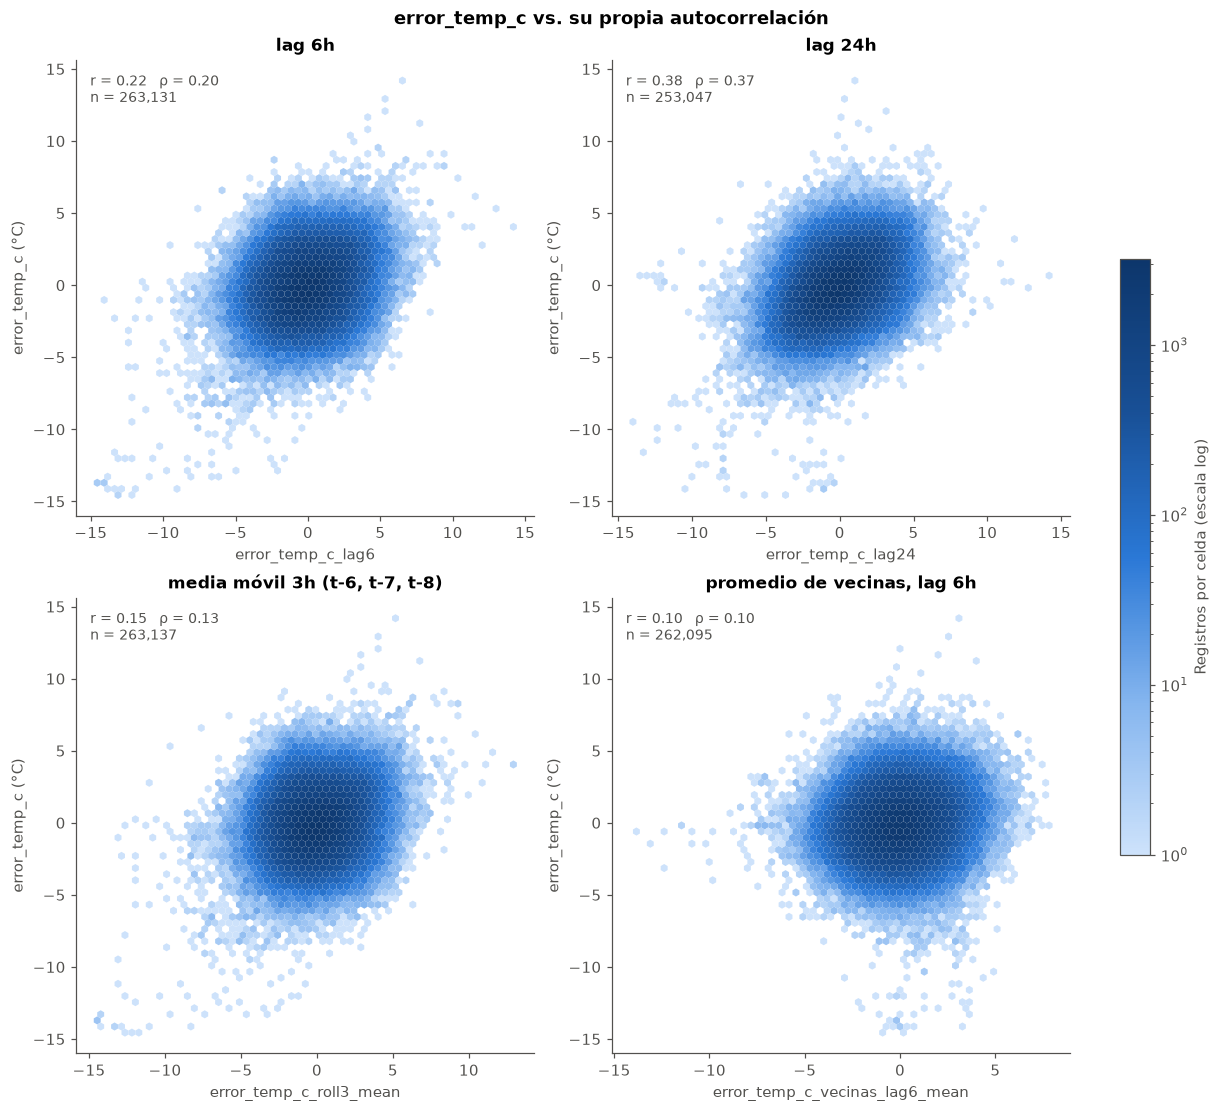

In [3]:
AUTOCORR = [
    ('error_temp_c_lag6', 'lag 6h'),
    ('error_temp_c_lag24', 'lag 24h'),
    ('error_temp_c_roll3_mean', 'media móvil 3h (t-6, t-7, t-8)'),
    ('error_temp_c_vecinas_lag6_mean', 'promedio de vecinas, lag 6h'),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
hbs = []
for ax, (col, etiqueta) in zip(axes.flat, AUTOCORR):
    hbs.append(hexbin_par(ax, datos, col, 'error_temp_c'))
    ax.set(title=etiqueta, xlabel=col, ylabel='error_temp_c (°C)')
fig.colorbar(escala_comun(hbs), ax=axes, shrink=0.6, label='Registros por celda (escala log)')
fig.suptitle('error_temp_c vs. su propia autocorrelación', fontweight='bold')
figuras['01_autocorrelacion_propia'] = fig
plt.show()


### Lectura

`lag24` es, de los cuatro, el más correlacionado (r = 0,38, ρ = 0,37) -visualmente se nota en el hexbin como la
nube más alargada sobre la diagonal de las cuatro-, seguido por `lag6` (r = 0,22). `roll3_mean` (r = 0,15) y el
promedio de vecinas (r = 0,10) quedan claramente por detrás. El orden coincide exactamente con el de la PACF de
la notebook 3 (lag24 > lag6 > lag48, con lag48 ya descartado del feature set): acá se ve el mismo patrón de forma
directa, sin pasar por un test estadístico -el ciclo diario (lag24) es la señal más fuerte que tiene el error
sobre sí mismo, más que la persistencia de corto plazo.

## 3. Lags de variables observadas (sensores)

Las 3 variables de sensores que se reintegraron para los modelos de árbol tras el hallazgo 6 de
`revision-pipeline-error.md` (`obs_rh_pct_lag6` ya tenía señal lineal propia vía CCF; `obs_dewpoint_c_lag6` y
`obs_windspeed_kmh_lag6` se agregaron igual para que Random Forest/Gradient Boosting evalúen interacciones no
lineales), todas en `shift(HORIZONTE)`. La dirección del viento es circular -no tiene sentido un scatter contra
un ángulo en grados- así que se muestra en dos vistas: el error medio por sector (reutilizando `sector_viento`,
calculado antes del lag) y el encoding cíclico (`sin`/`cos`) que sí se usa como feature, cada uno contra
`error_temp_c`.

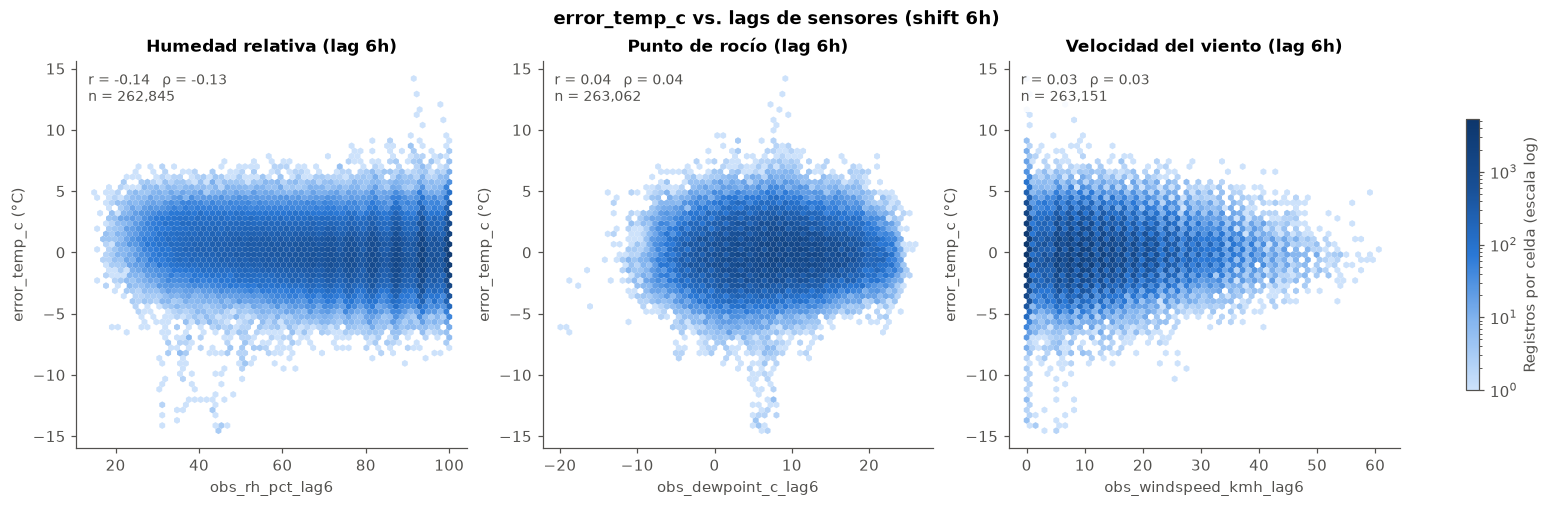

In [4]:
SENSORES = [
    ('obs_rh_pct_lag6', 'Humedad relativa (lag 6h)'),
    ('obs_dewpoint_c_lag6', 'Punto de rocío (lag 6h)'),
    ('obs_windspeed_kmh_lag6', 'Velocidad del viento (lag 6h)'),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True)
hbs = []
for ax, (col, etiqueta) in zip(axes, SENSORES):
    hbs.append(hexbin_par(ax, datos, col, 'error_temp_c'))
    ax.set(title=etiqueta, xlabel=col, ylabel='error_temp_c (°C)')
fig.colorbar(escala_comun(hbs), ax=axes, shrink=0.7, label='Registros por celda (escala log)')
fig.suptitle('error_temp_c vs. lags de sensores (shift 6h)', fontweight='bold')
figuras['02_sensores_lag6'] = fig
plt.show()


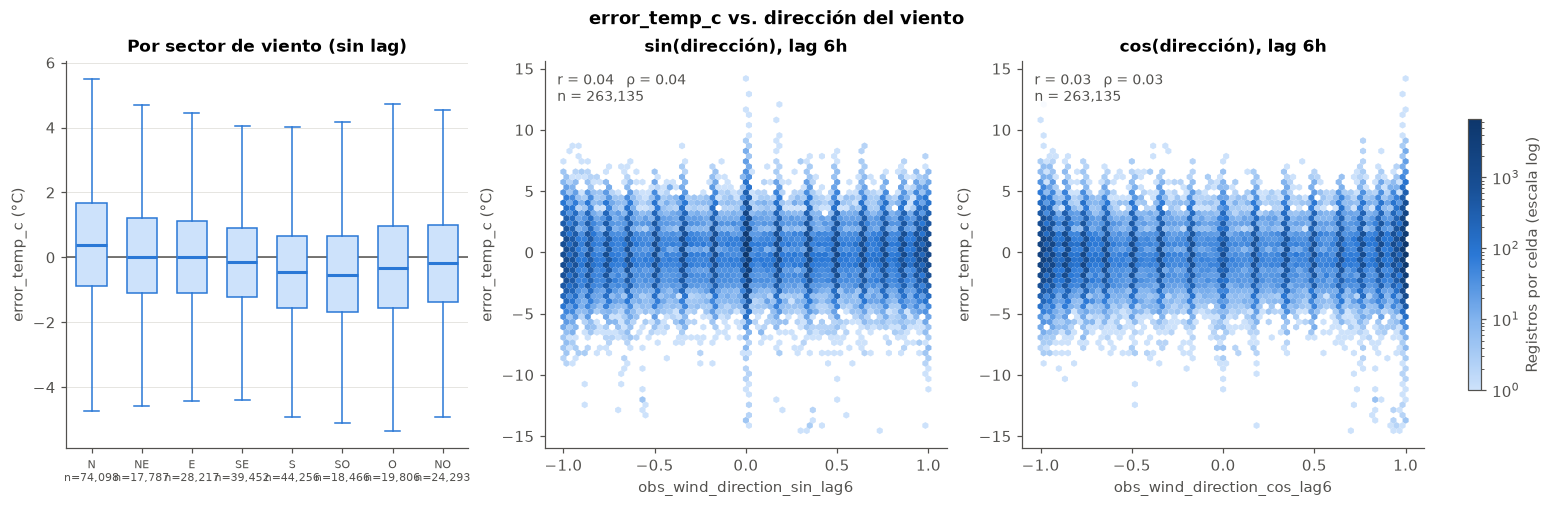

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True)

d = datos.dropna(subset=['sector_viento', 'error_temp_c'])
grupos = [d.loc[d['sector_viento'] == s, 'error_temp_c'].values for s in sectores]
axes[0].axhline(0, color=GRIS_TEXTO, lw=1)
etq_n = [f'{s}\nn={len(g):,}' for s, g in zip(sectores, grupos)]
axes[0].boxplot(grupos, tick_labels=etq_n, showfliers=False, widths=0.6, patch_artist=True,
                boxprops=dict(facecolor='#cde2fb', edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
                whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL))
axes[0].set(title='Por sector de viento (sin lag)', ylabel='error_temp_c (°C)')
axes[0].tick_params(axis='x', labelsize=7)
axes[0].grid(axis='x', visible=False)

hbs = [
    hexbin_par(axes[1], datos, 'obs_wind_direction_sin_lag6', 'error_temp_c'),
    hexbin_par(axes[2], datos, 'obs_wind_direction_cos_lag6', 'error_temp_c'),
]
axes[1].set(title='sin(dirección), lag 6h', xlabel='obs_wind_direction_sin_lag6', ylabel='error_temp_c (°C)')
axes[2].set(title='cos(dirección), lag 6h', xlabel='obs_wind_direction_cos_lag6', ylabel='error_temp_c (°C)')
fig.colorbar(escala_comun(hbs), ax=axes[1:], shrink=0.7, label='Registros por celda (escala log)')
fig.suptitle('error_temp_c vs. dirección del viento', fontweight='bold')
figuras['03_direccion_viento'] = fig
plt.show()


### Lectura

De los tres sensores, `obs_rh_pct_lag6` es el único con una correlación que se nota a ojo (r = −0,140, ρ = −0,130):
más humedad 6h antes, el pronóstico tiende a sobreestimar menos (o subestimar más) la temperatura -coherente con
que el aire húmedo amortigua los cambios térmicos que el pronóstico de grilla gruesa puede no estar anticipando.
`obs_dewpoint_c_lag6` (r = 0,037) y `obs_windspeed_kmh_lag6` (r = 0,031) son prácticamente ruido en este corte
bivariado -consistente con el hallazgo 6 de `revision-pipeline-error.md`, que ya había encontrado que sólo
`obs_rh_pct_lag6` tiene señal **lineal** real contra `error_temp_c`; las otras dos sólo se reintegraron para que
los modelos de árbol evalúen interacciones no lineales que un r/ρ simple no puede detectar.

La dirección del viento cuenta una historia más clara en el boxplot por sector (sin lag) que en el scatter
cíclico con lag: la mediana del error va de **+0,39 °C con viento del norte** a **−0,55 °C con viento del
suroeste** -coherente con advección de aire frío desde Canadá (el pronóstico todavía no la capturó del todo,
sobreestima) vs. aire cálido/húmedo del Golfo (el pronóstico se queda corto, subestima). El encoding cíclico ya
laggeado (`sin`/`cos` a 6h) diluye bastante esa señal (r = 0,043 y 0,035): parte de la información de dirección
se pierde entre que ya pasaron 6h y que acá se mide sin filtrar por velocidad (una calma con cualquier dirección
sigue entrando en el promedio).

## 4. Valores pronosticados

`fcst_temp_c` y `fcst_pop_pct` no son features "de historia" como los anteriores -son el propio pronóstico que se
quiere corregir-, pero son el tipo de variable que más le aportó a los modelos de árbol en `7_modelado_global.ipynb`
(`fcst_pop_pct` quedó 3º en SHAP de Random Forest). Se suman acá, además, los otros tres valores pronosticados
que `mediciones_limpias.csv` ya trae -`fcst_rh_pct`, `fcst_dewpoint_c`, `fcst_windspeed_kmh`- y que **nunca se
evaluaron como candidatos** en ningún lado del pipeline (no están en `FEATURES_NUMERICAS` de
`7_modelado_global.ipynb`): la intuición es que el pronóstico de las otras variables puede funcionar como un
proxy de "qué tan bien está viendo el modelo climático esta situación en particular", y eso podría asociarse
con el error de temperatura aunque no haya una relación física directa. `fcst_pop_pct` se agrupa en los mismos
rangos que `2_relaciones-bivariadas.ipynb` (sección 6) para que el gráfico sea comparable con el de esa
notebook.


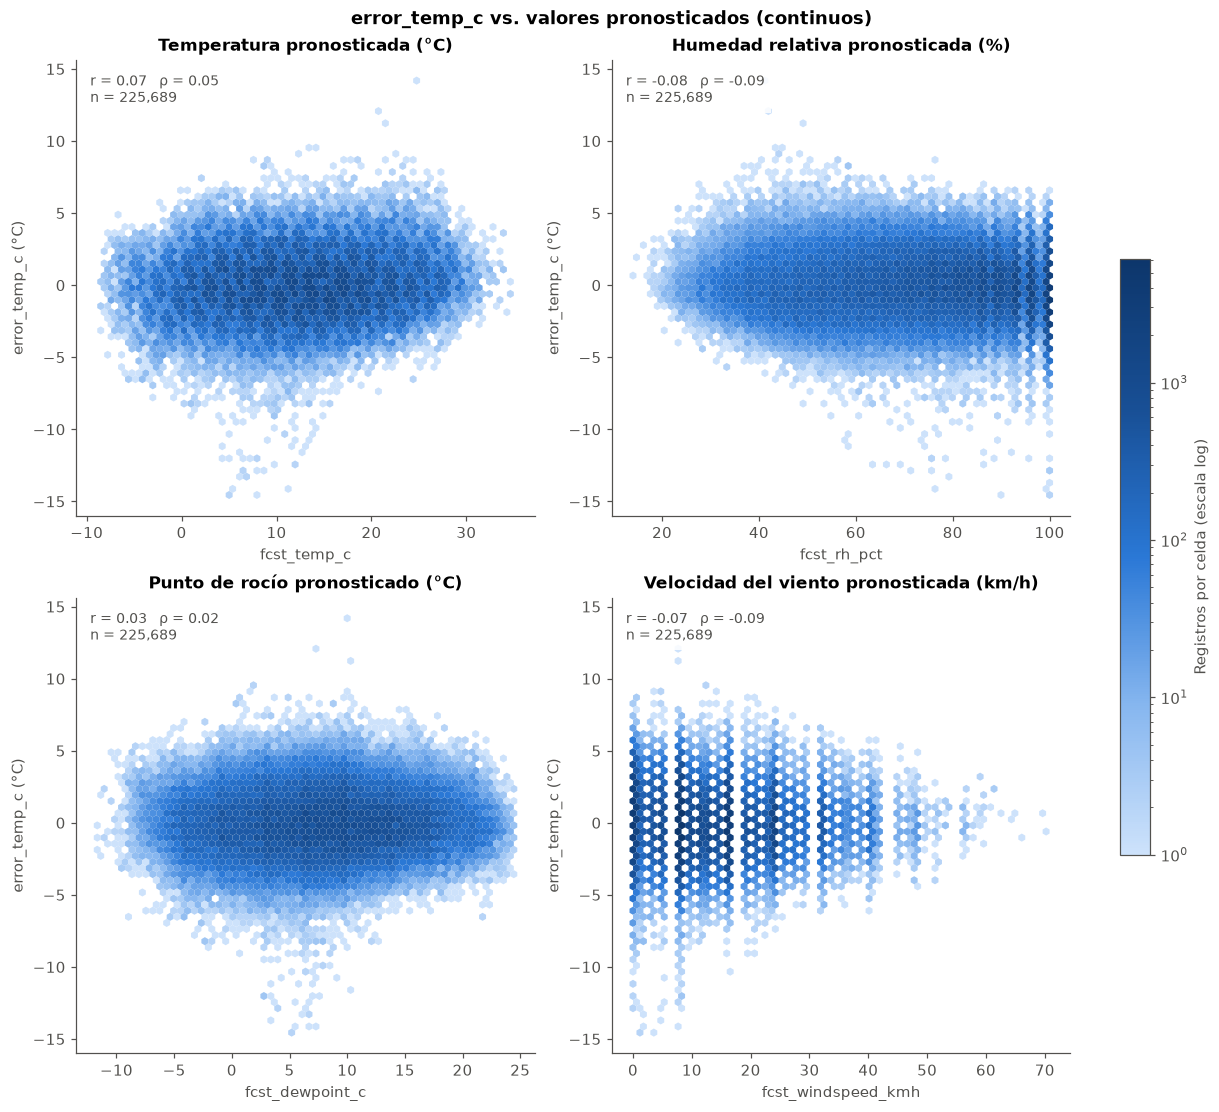

In [6]:
PRONOSTICADOS = [
    ('fcst_temp_c', 'Temperatura pronosticada (°C)'),
    ('fcst_rh_pct', 'Humedad relativa pronosticada (%)'),
    ('fcst_dewpoint_c', 'Punto de rocío pronosticado (°C)'),
    ('fcst_windspeed_kmh', 'Velocidad del viento pronosticada (km/h)'),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
hbs = []
for ax, (col, etiqueta) in zip(axes.flat, PRONOSTICADOS):
    hbs.append(hexbin_par(ax, datos, col, 'error_temp_c'))
    ax.set(title=etiqueta, xlabel=col, ylabel='error_temp_c (°C)')
fig.colorbar(escala_comun(hbs), ax=axes, shrink=0.6, label='Registros por celda (escala log)')
fig.suptitle('error_temp_c vs. valores pronosticados (continuos)', fontweight='bold')
figuras['04_valores_pronosticados'] = fig
plt.show()


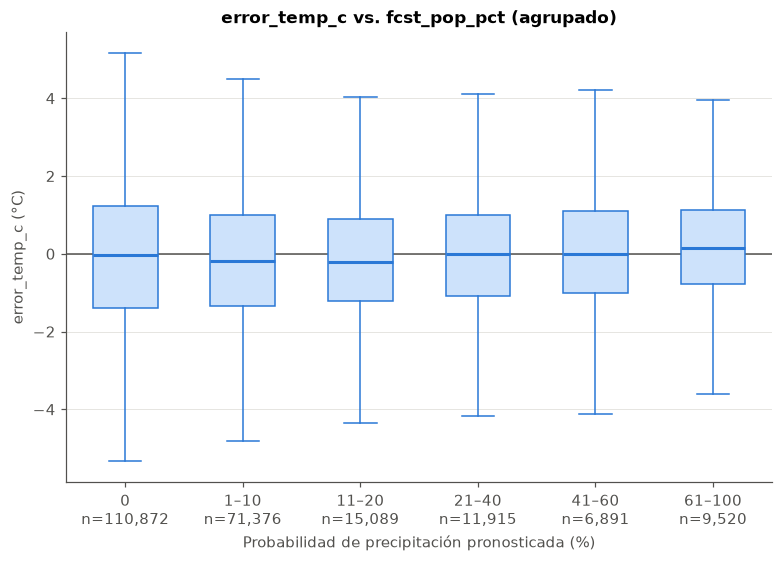

In [7]:
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)

cortes_pop = [-0.1, 0, 10, 20, 40, 60, 100]
etiquetas_pop = ['0', '1–10', '11–20', '21–40', '41–60', '61–100']
datos['pop_rango'] = pd.cut(datos['fcst_pop_pct'], cortes_pop, labels=etiquetas_pop)

d = datos.dropna(subset=['pop_rango', 'error_temp_c'])
grupos = [g['error_temp_c'].values for _, g in d.groupby('pop_rango', observed=False)]
ax.axhline(0, color=GRIS_TEXTO, lw=1)
etq_n = [f'{e}\nn={len(g):,}' for e, g in zip(etiquetas_pop, grupos)]
ax.boxplot(grupos, tick_labels=etq_n, showfliers=False, widths=0.55, patch_artist=True,
           boxprops=dict(facecolor='#cde2fb', edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
           whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL))
ax.set(title='error_temp_c vs. fcst_pop_pct (agrupado)', xlabel='Probabilidad de precipitación pronosticada (%)',
       ylabel='error_temp_c (°C)')
ax.grid(axis='x', visible=False)
figuras['04b_pop_pct'] = fig
plt.show()


### Lectura

`fcst_temp_c` (r = 0,066, ρ = 0,049) y `fcst_pop_pct` (r = 0,037, ρ ≈ 0,000, la misma brecha lineal/rango ya
comentada -señal no lineal, no lineal real) siguen débiles. **Pero `fcst_rh_pct` (r = −0,081, ρ = −0,091) y
`fcst_windspeed_kmh` (r = −0,068, ρ = −0,087) resultan más correlacionados que el propio `fcst_temp_c`**, y a
diferencia de `fcst_pop_pct`, acá Pearson y Spearman coinciden en signo y magnitud -no es un efecto de unos
pocos puntos, es una relación monótona real, aunque chica-. La lectura física es parecida a la de
`obs_rh_pct_lag6` (sección 3): cuando el modelo climático pronostica más humedad o más viento de lo habitual
para esa hora, tiende a sobreestimar menos (o subestimar más) la temperatura -son señales de que el modelo
numérico está viendo una situación sinóptica distinta a la "típica", y esa misma distinción parece filtrarse
al error de temperatura. `fcst_dewpoint_c` (r = 0,025) es, de los 5, el único realmente chico.

Esto es un hallazgo nuevo, no algo que ya estuviera probado en otro lado: ni `fcst_rh_pct` ni
`fcst_windspeed_kmh` están en `FEATURES_NUMERICAS` de `7_modelado_global.ipynb` hoy. Quedó anotado como
hallazgo 19 de `revision-pipeline-error.md` para evaluarlos como candidatos cuando se llegue a esa notebook.


## 5. Hora local y su encoding cíclico

Tres vistas de la misma variable: la media + rango intercuartílico por hora (línea/banda, igual que
`2_relaciones-bivariadas.ipynb` sección 6), un reloj polar que muestra por qué tiene sentido codificarla de forma
cíclica -la hora 23 y la hora 0 son vecinas en la vida real, no extremos opuestos de una escala-, y el scatter
contra `hora_sin`/`hora_cos`, que es la forma en la que la hora efectivamente entra como feature numérica.

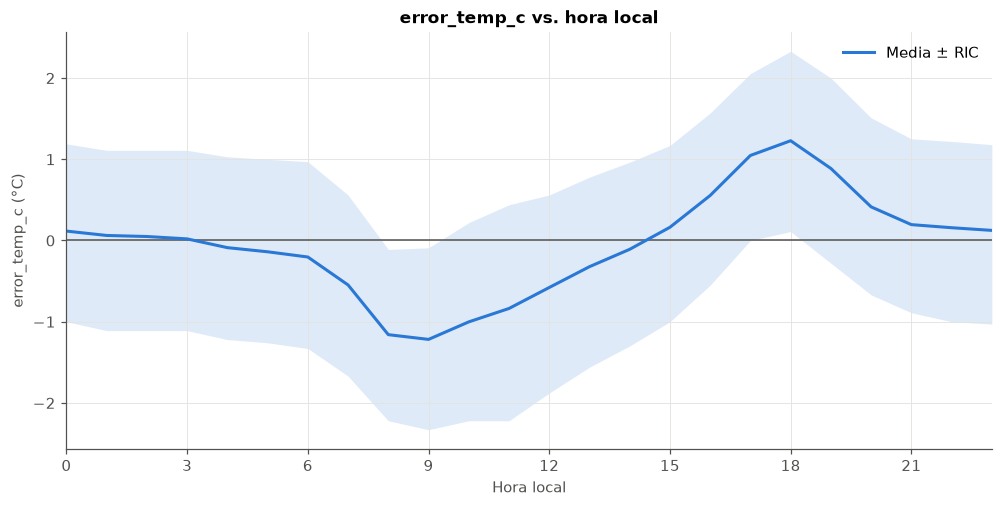

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.axhline(0, color=GRIS_TEXTO, lw=1)
banda_por_hora(ax, datos, 'error_temp_c', AZUL, 'Media ± RIC')
ax.set(title='error_temp_c vs. hora local', xlabel='Hora local', ylabel='error_temp_c (°C)',
       xticks=range(0, 24, 3), xlim=(0, 23))
ax.legend(frameon=False)
figuras['05_error_por_hora'] = fig
plt.show()


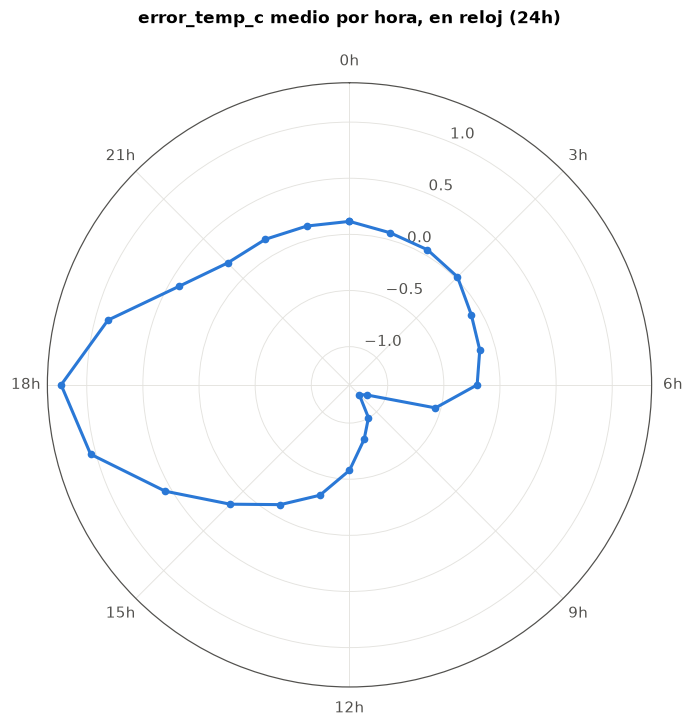

In [9]:
media_por_hora = datos.groupby('hora_local')['error_temp_c'].mean()
angulos = 2 * np.pi * media_por_hora.index / 24

fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw={'projection': 'polar'}, constrained_layout=True)
ax.plot(np.append(angulos, angulos[0]), np.append(media_por_hora.values, media_por_hora.values[0]),
        color=AZUL, lw=2, marker='o', markersize=4)
ax.axhline(0, color=GRIS_TEXTO, lw=0.8) if False else None  # el radio 0 ya es visible como círculo de grilla
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)
ax.set_xticks(2 * np.pi * np.arange(0, 24, 3) / 24)
ax.set_xticklabels([f'{h}h' for h in range(0, 24, 3)])
ax.set_title('error_temp_c medio por hora, en reloj (24h)', pad=20)
figuras['06_reloj_error_por_hora'] = fig
plt.show()


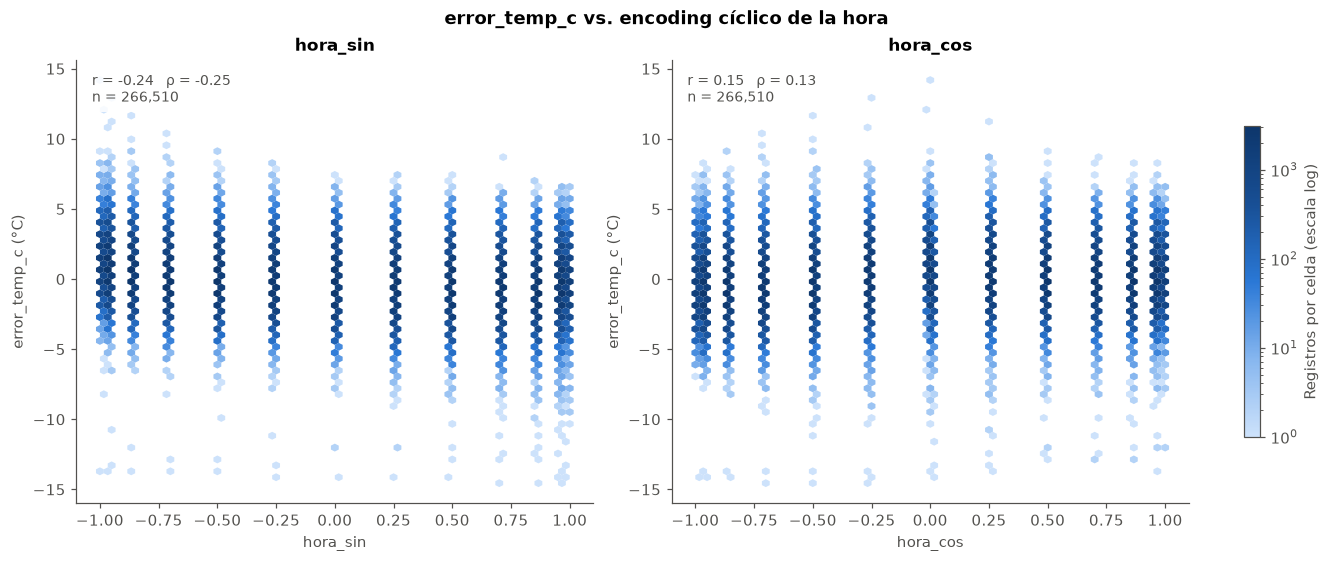

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
hbs = [
    hexbin_par(axes[0], datos, 'hora_sin', 'error_temp_c'),
    hexbin_par(axes[1], datos, 'hora_cos', 'error_temp_c'),
]
axes[0].set(title='hora_sin', xlabel='hora_sin', ylabel='error_temp_c (°C)')
axes[1].set(title='hora_cos', xlabel='hora_cos', ylabel='error_temp_c (°C)')
fig.colorbar(escala_comun(hbs), ax=axes, shrink=0.7, label='Registros por celda (escala log)')
fig.suptitle('error_temp_c vs. encoding cíclico de la hora', fontweight='bold')
figuras['07_hora_ciclica'] = fig
plt.show()


### Lectura

La hora resulta ser, sola, casi tan fuerte como `lag24`: `hora_sin` (r = −0,243) es la **segunda** variable más
correlacionada de toda esta notebook, y `hora_cos` (r = 0,145) queda a la par de `roll3_mean`. La banda por hora y
el reloj polar muestran el mismo patrón, dos formas de mirarlo: con la convención `fcst − obs` (positivo =
sobreestima), el pronóstico **subestima** más fuerte a media mañana (sesgo −1,22 °C a las 9h) y **sobreestima**
más a la tarde-noche (sesgo +1,23 °C a las 18h). Son casi los mismos números y las mismas dos horas que ya había
encontrado `2_relaciones-bivariadas.ipynb` (sección 9, sobre un cohorte y una definición de error distintas: sin
filtrar por intermitencia, sin imputar, con el error crudo `fcst - obs` de todos los pares observación-pronóstico)
-−1,36 °C a las 9h y +1,34 °C a las 18h-, lo que es una buena señal cruzada: dos pipelines distintos, calculando
el error de formas distintas, coinciden en cuáles son las horas más difíciles y en qué dirección falla cada una.

El reloj deja ver además **por qué** alcanza con un solo par seno/coseno: la forma es un único lóbulo por día, sin
rebotes secundarios -si hubiera, por ejemplo, un pico a media mañana y otro distinto a la madrugada, un armónico
simple (período 24h) no lo capturaría y haría falta sumar `sin(2·ángulo)`/`cos(2·ángulo)`. No es el caso acá.

## 6. Síntesis: ranking de todas las variables candidatas

Mismo r de Pearson y ρ de Spearman que ya se calculó en cada panel (sobre todas las filas con ambos valores
presentes), ordenado por `|r|` para tener un único punto de comparación entre los 4 grupos. La dirección del
viento entra dos veces (`sin`/`cos` por separado, ninguno de los dos tiene sentido resumir en un solo número).

In [11]:
CANDIDATAS = [
    ('error_temp_c_lag6', 'Autocorrelación propia', 'lag 6h'),
    ('error_temp_c_lag24', 'Autocorrelación propia', 'lag 24h'),
    ('error_temp_c_roll3_mean', 'Autocorrelación propia', 'media móvil 3h'),
    ('error_temp_c_vecinas_lag6_mean', 'Autocorrelación propia', 'promedio de vecinas'),
    ('obs_rh_pct_lag6', 'Sensores (lag 6h)', 'humedad relativa'),
    ('obs_dewpoint_c_lag6', 'Sensores (lag 6h)', 'punto de rocío'),
    ('obs_windspeed_kmh_lag6', 'Sensores (lag 6h)', 'velocidad del viento'),
    ('obs_wind_direction_sin_lag6', 'Sensores (lag 6h)', 'dirección del viento (sin)'),
    ('obs_wind_direction_cos_lag6', 'Sensores (lag 6h)', 'dirección del viento (cos)'),
    ('fcst_temp_c', 'Pronóstico', 'temperatura pronosticada'),
    ('fcst_pop_pct', 'Pronóstico', 'prob. de precipitación'),
    ('fcst_rh_pct', 'Pronóstico', 'humedad pronosticada'),
    ('fcst_dewpoint_c', 'Pronóstico', 'punto de rocío pronosticado'),
    ('fcst_windspeed_kmh', 'Pronóstico', 'viento pronosticado'),
    ('hora_sin', 'Hora local', 'hora (sin)'),
    ('hora_cos', 'Hora local', 'hora (cos)'),
]

filas = []
for col, grupo, etiqueta in CANDIDATAS:
    d = datos[[col, 'error_temp_c']].dropna()
    r = d[col].corr(d['error_temp_c'])
    rho = d[col].corr(d['error_temp_c'], method='spearman')
    filas.append(dict(grupo=grupo, variable=etiqueta, columna=col, r=round(r, 3), rho=round(rho, 3), n=len(d)))

tabla_ranking = pd.DataFrame(filas).sort_values('r', key=lambda s: s.abs(), ascending=False).reset_index(drop=True)
tabla_ranking


,grupo,variable,columna,r,rho,n
0,Autocorrelación propia,lag 24h,error_temp_c_lag24,0.377,0.368,253047
1,Hora local,hora (sin),hora_sin,-0.243,-0.250,266510
2,Autocorrelación propia,lag 6h,error_temp_c_lag6,0.222,0.201,263131
3,Autocorrelación propia,media móvil 3h,error_temp_c_roll3_mean,0.150,0.128,263137
4,Hora local,hora (cos),hora_cos,0.145,0.135,266510
5,Sensores (lag 6h),humedad relativa,obs_rh_pct_lag6,-0.140,-0.130,262845
6,Autocorrelación propia,promedio de vecinas,error_temp_c_vecinas_lag6_mean,0.103,0.100,262095
7,Pronóstico,humedad pronosticada,fcst_rh_pct,-0.081,-0.091,225689
8,Pronóstico,viento pronosticado,fcst_windspeed_kmh,-0.068,-0.087,225689
9,Pronóstico,temperatura pronosticada,fcst_temp_c,0.066,0.049,225689


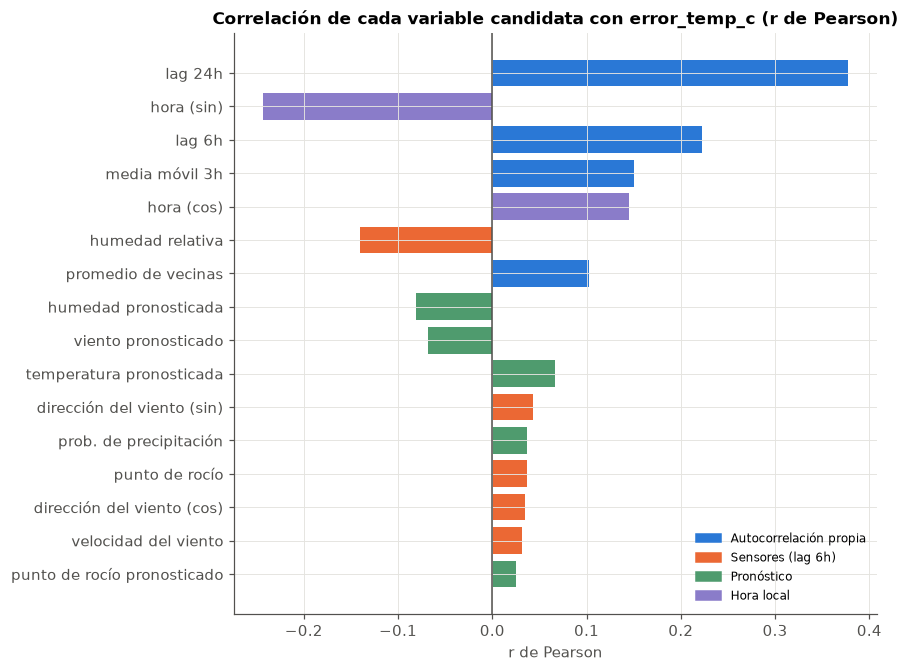

In [12]:
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
orden = tabla_ranking.sort_values('r', key=lambda s: s.abs())
colores = {'Autocorrelación propia': AZUL, 'Sensores (lag 6h)': NARANJA,
           'Pronóstico': '#4f9b6e', 'Hora local': '#8a7cc9'}
ax.barh(orden['variable'], orden['r'], color=[colores[g] for g in orden['grupo']])
ax.axvline(0, color=GRIS_TEXTO, lw=1)
ax.set(title='Correlación de cada variable candidata con error_temp_c (r de Pearson)', xlabel='r de Pearson')

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colores.values()]
ax.legend(handles, colores.keys(), frameon=False, loc='lower right', fontsize=8)
figuras['08_ranking_candidatas'] = fig
plt.show()


### Lectura

El ranking tiene un escalón bastante marcado. Arriba, cuatro variables con |r| entre 0,15 y 0,38:
`error_temp_c_lag24` (0,38), `hora_sin` (−0,24), `error_temp_c_lag6` (0,22), y `error_temp_c_roll3_mean`/`hora_cos`
empatadas alrededor de 0,15. Abajo, un escalón de variables con |r| entre 0,06 y 0,14: `obs_rh_pct_lag6`
(−0,14), `error_temp_c_vecinas_lag6_mean` (0,10), y los dos hallazgos nuevos de la sección 4 -`fcst_rh_pct`
(−0,08) y `fcst_windspeed_kmh` (−0,07)-, que quedan por delante incluso de `fcst_temp_c` (0,07). El resto
(direcciones de viento laggeadas, `obs_dewpoint_c_lag6`, `fcst_pop_pct`, `obs_windspeed_kmh_lag6`,
`fcst_dewpoint_c`) queda por debajo de 0,04, prácticamente ruido.

Los 5 de arriba coinciden, variable por variable, con lo que ya había encontrado `8_interpretabilidad.ipynb`
por SHAP/feature importance -`error_temp_c_lag24`, `hora_sin`/`hora_cos` y `error_temp_c_lag6` como las
features más importantes de los dos modelos finales- pero llegando ahí por un camino completamente distinto
(correlación bivariada simple, sin entrenar ningún modelo). Es una buena confirmación cruzada: el feature
engineering de la notebook 3 no eligió mal qué priorizar. La única discrepancia aparente es `fcst_pop_pct`,
que acá queda casi en el fondo de la tabla pero fue 3º en SHAP de Random Forest -ya se vio en la sección 4
que es exactamente el tipo de señal no lineal que una correlación simple no puede capturar, así que no es una
contradicción, es el límite esperado de este análisis-; por la misma razón, que `fcst_rh_pct` y
`fcst_windspeed_kmh` salgan con señal lineal real acá no garantiza que le aporten a los modelos de árbol, pero
sí los vuelve candidatos más fuertes que `fcst_pop_pct` para los modelos **lineales**, algo que nunca se había
evaluado.


## 7. Exportación

Se guardan la tabla de ranking y las figuras, mismo criterio que el resto del TP.

In [13]:
import os

os.makedirs(OUT, exist_ok=True)
tabla_ranking.to_csv(OUT + 'ranking_correlaciones_error_temp_c.csv', index=False)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')

print(f'Guardados: 1 tabla y {len(figuras)} figuras en {OUT}')


Guardados: 1 tabla y 9 figuras en ../data/out/correlaciones_error_temp_c/
